# Stokes: a synthetic polarization image

The polarization of light at a pixel is described by its **Stokes vector**
`[S0, S1, S2, S3]`:

- S0 is the total intensity;
- S1 compares horizontal and vertical polarization, S2 compares +45° and −45°;
- S3 measures circular polarization, its sign giving the handedness.

A Stokes vector is physically valid when S0 ≥ √(S1² + S2² + S3²): the polarized part
cannot be brighter than the light itself. The **Stokes** model writes a polarization image
as a sum of terms *non-negative spatial map × valid Stokes vector*
(see [Stokes](../models/stokes.md)).

## The data

40 × 50 pixels, R = 3 terms, spatial maps of rank L = 2 (two blobs each), and one random
fully polarized state per term. We add 1% noise.

In [1]:
import numpy as np

from pybbtd import Stokes
from pybbtd.btd import factors_to_tensor
from pybbtd.datasets import make_blob_factors
from pybbtd.stokes import (
    generate_stokes_factors,
    is_valid_stokes,
    validate_stokes_tensor,
)
from pybbtd.visualization import plot_error, plot_stokes_terms

np.random.seed(0)
R, L = 3, 2
model = Stokes((40, 50), R=R, L=L)

A0, B0 = make_blob_factors(40, 50, R, L, seed=0)
_, _, C0 = generate_stokes_factors(model.dims, R, model.L)  # one Stokes vector per term
T0 = factors_to_tensor(A0, B0, C0, model.get_constraint_matrix())
T = T0 + 0.01 * np.linalg.norm(T0) / np.sqrt(T0.size) * np.random.randn(*T0.shape)

The clean image is valid everywhere. The true states are fully polarized, which puts them
right on the edge of the valid set, so the noise pushes many pixels just outside it:

In [2]:
print("clean data valid:", validate_stokes_tensor(T0))
print("noisy data valid:", validate_stokes_tensor(T))

clean data valid: True
noisy data valid: False


  print("noisy data valid:", validate_stokes_tensor(T))


The true terms, drawn with {func}`~pybbtd.visualization.plot_stokes_terms`: spatial maps
on top, polarization ellipses below:

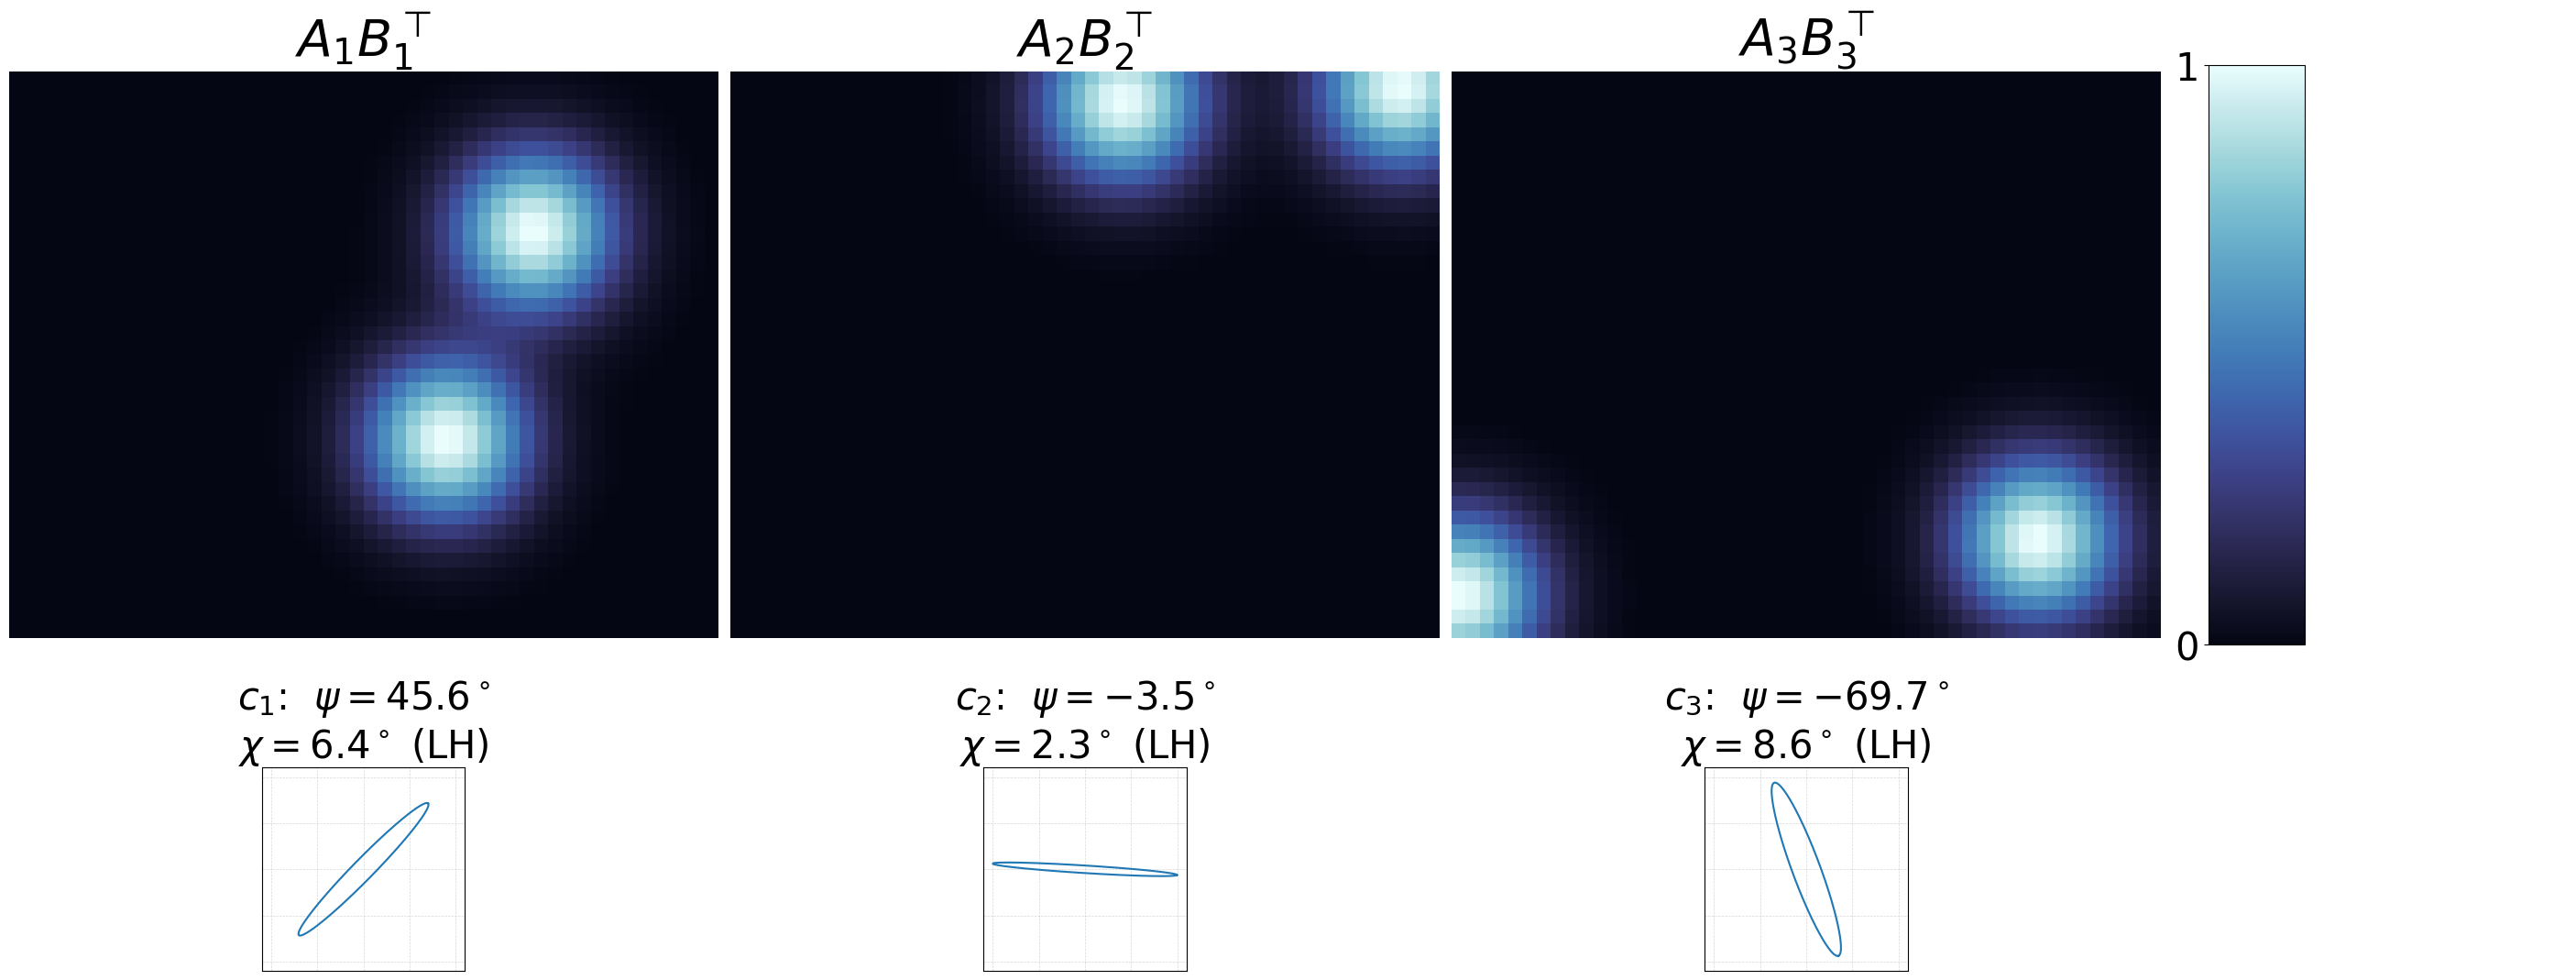

In [3]:
plot_stokes_terms(A0, B0, C0, R, L)

## Fit the model

The AO-ADMM solver keeps the spatial maps non-negative and every Stokes vector valid.
The K-means initialization groups pixels with similar Stokes vectors.

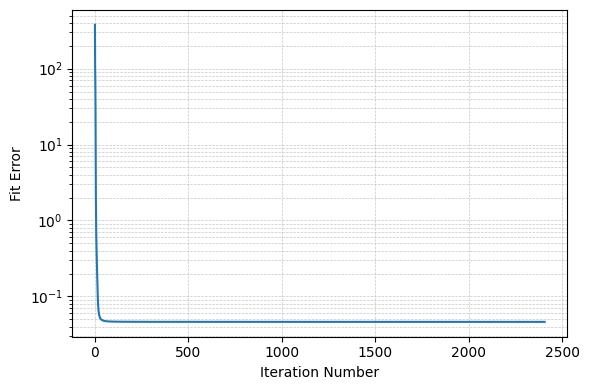

In [4]:
model.fit(T, init="kmeans", max_iter=3000, rel_tol=1e-10, abs_tol=0)
plot_error(model.fit_error)

## Check the result

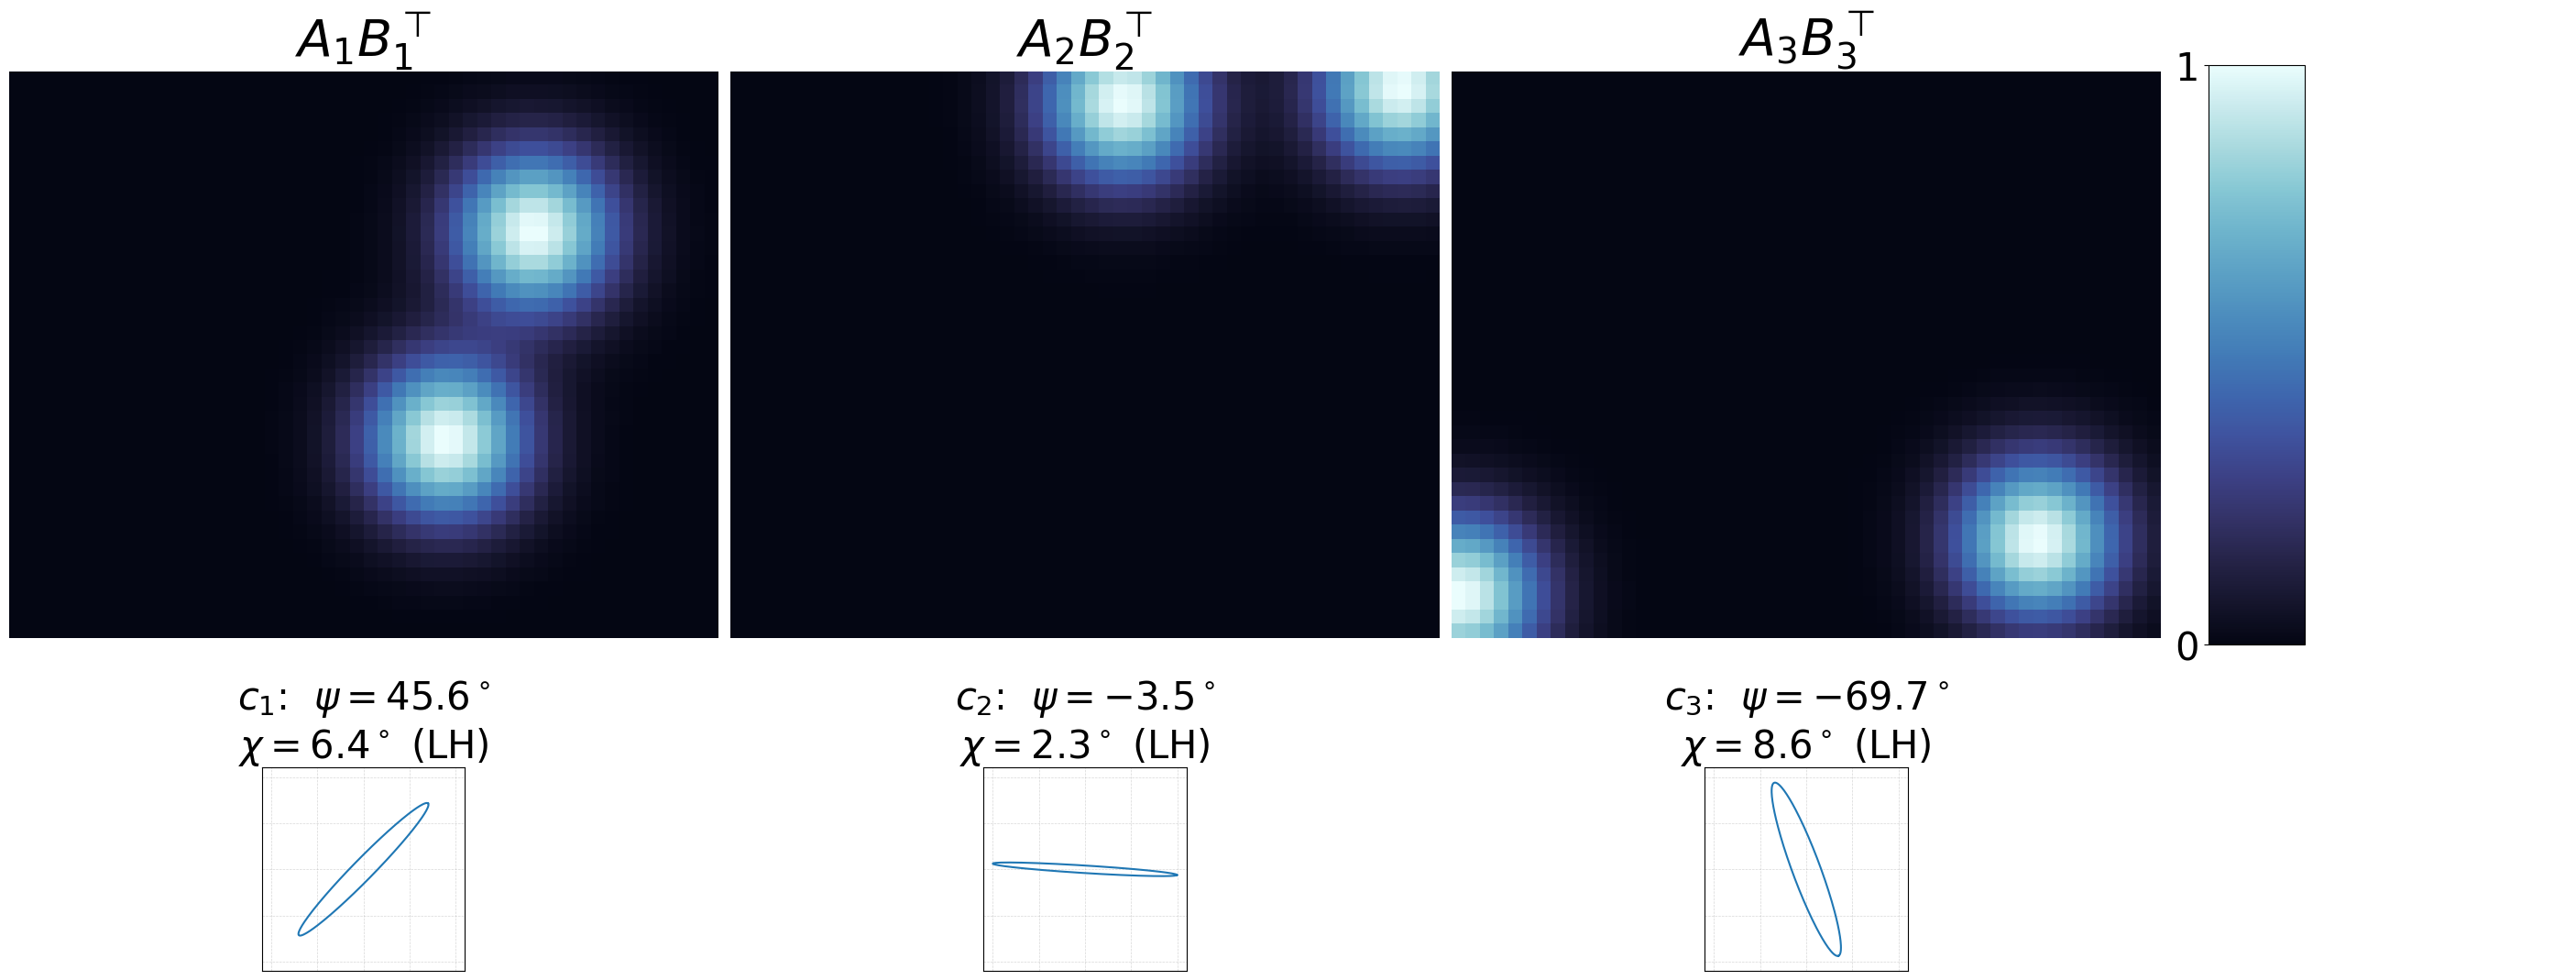

In [5]:
A, B, C = model.factors
plot_stokes_terms(A, B, C, R, L)

The recovered Stokes vectors, scaled to S0 = 1, next to the true ones (the order of the
terms can differ):

In [6]:
np.set_printoptions(precision=3, suppress=True)
print("true:\n", C0 / C0[0])
print("recovered:\n", C / C[0])
print("all valid:", all(is_valid_stokes(c) for c in C.T))

true:
 [[ 1.     1.     1.   ]
 [-0.019  0.989 -0.724]
 [ 0.975 -0.123 -0.623]
 [ 0.221  0.082  0.297]]
recovered:
 [[ 1.     1.     1.   ]
 [-0.019  0.989 -0.724]
 [ 0.975 -0.123 -0.623]
 [ 0.221  0.081  0.297]]
all valid: True


The fitted tensor is closer to the clean image than the noisy data are (1% away):

In [7]:
np.linalg.norm(model.tensor - T0) / np.linalg.norm(T0)

np.float64(0.00243358439073403)